In [ ]:
import os
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tqdm import tqdm

# Input path
APTOS_ROOT = Path("/kaggle/input/competitions/aptos2019-blindness-detection")
INPUT_DIR = APTOS_ROOT / "train_images"
LABELS_CSV = APTOS_ROOT / "train.csv"

# Output path
OUTPUT_DIR = Path("/kaggle/working/aptos_processed")
IMG_DIR = OUTPUT_DIR / "images_512"
IMG_DIR.mkdir(parents=True, exist_ok=True)

# Config
SIZE = 512
WORKERS = 4
SEED = 42

In [2]:
# Ben Graham's crop - Removes black border from images
def crop_image_from_gray(img, tol=7):
    """Ben Graham's crop — remove black border by thresholding."""
    if img.ndim == 2:
        mask = img > tol
        return img[np.ix_(mask.any(1), mask.any(0))]
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    mask = gray > tol
    if mask.sum() == 0:
        return img
    return img[np.ix_(mask.any(1), mask.any(0))]

# CLAHE - Enhance contrast
def apply_clahe(rgb_img, clip_limit=2.0, tile_grid=(8, 8)):
    """CLAHE on the L channel of LAB — preserves color, boosts local contrast."""
    lab = cv2.cvtColor(rgb_img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid)
    l = clahe.apply(l)
    lab = cv2.merge((l, a, b))
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

# Remove black circle border and resize to 512x512
def crop_circle_and_resize(rgb_img, size=512):
    """Circular mask + resize to (size, size)."""
    h, w = rgb_img.shape[:2]
    r = min(h, w) // 2
    mask = np.zeros((h, w), dtype=np.uint8)
    cv2.circle(mask, (w // 2, h // 2), r, 255, -1)
    mask = cv2.GaussianBlur(mask, (51, 51), 0)

    rgb_float = rgb_img.astype(np.float32)
    mask_3ch = mask[..., None].astype(np.float32) / 255.0
    masked = (rgb_float * mask_3ch + 255.0 * (1 - mask_3ch)).astype(np.uint8)

    return cv2.resize(masked, (size, size), interpolation=cv2.INTER_AREA)

# Save as .png file
def preprocess_one(args):
    src_path, dst_path, size = args
    try:
        img = cv2.imread(src_path)
        if img is None:
            return (src_path, False, "unreadable")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = crop_image_from_gray(img)
        img = apply_clahe(img, 2.0, (8, 8))
        img = crop_circle_and_resize(img, size=size)
        out_bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
        cv2.imwrite(dst_path, out_bgr, [cv2.IMWRITE_PNG_COMPRESSION, 3])
        return (src_path, True, None)
    except Exception as e:
        return (src_path, False, str(e))

In [3]:
# Load labels
df = pd.read_csv(LABELS_CSV)
df.columns = [c.strip().lower() for c in df.columns]
df = df[["id_code", "diagnosis"]]
print(f"Loaded {len(df)} rows")
print(df["diagnosis"].value_counts().sort_index())

# Build task list
tasks, kept_rows = [], []
for _, row in df.iterrows():
    src = INPUT_DIR / f"{row['id_code']}.png"
    if not src.exists():
        print(f"[WARN] Missing: {row['id_code']}")
        continue
    dst = IMG_DIR / f"{row['id_code']}.png"
    tasks.append((str(src), str(dst), SIZE))
    kept_rows.append({
        "id_code":   row["id_code"],
        "diagnosis": int(row["diagnosis"]),
        "filepath":  str(dst),
    })

print(f"\nPreprocessing {len(tasks)} images with {WORKERS} workers...")

failures = []
with ProcessPoolExecutor(max_workers=WORKERS) as ex:
    futures = [ex.submit(preprocess_one, t) for t in tasks]
    for fut in tqdm(as_completed(futures), total=len(futures), desc="Preprocessing"):
        src, ok, err = fut.result()
        if not ok:
            failures.append((src, err))

if failures:
    print(f"[WARN] {len(failures)} failures (showing first 5):")
    for f in failures[:5]:
        print("   ", f)

print("Done.")

Loaded 3662 rows
diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64

Preprocessing 3662 images with 4 workers...


Preprocessing: 100%|██████████| 3662/3662 [14:01<00:00,  4.35it/s]


Done.


In [4]:
clean_df = pd.DataFrame(kept_rows)
clean_df = clean_df[clean_df["filepath"].apply(os.path.exists)].reset_index(drop=True)
print(f"Successfully processed: {len(clean_df)} / {len(df)} images")

# 80/10/10 split (still keeps the propotion)
train_df, temp_df = train_test_split(
    clean_df, test_size=0.20, stratify=clean_df["diagnosis"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["diagnosis"], random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

train_df.to_csv(OUTPUT_DIR / "train.csv", index=False)
val_df.to_csv(OUTPUT_DIR / "val.csv",     index=False)
test_df.to_csv(OUTPUT_DIR / "test.csv",   index=False)

print(f"\nSplit sizes: train={len(train_df)}  val={len(val_df)}  test={len(test_df)}")
for name, split in [("train", train_df), ("val", val_df), ("test", test_df)]:
    counts = split["diagnosis"].value_counts().sort_index()
    pct = (counts / len(split) * 100).round(2)
    print(f"  {name:5s} -> " +
          ", ".join(f"{k}:{v}({p}%)" for k, v, p in
                    zip(counts.index, counts.values, pct.values)))

Successfully processed: 3662 / 3662 images

Split sizes: train=2929  val=366  test=367
  train -> 0:1444(49.3%), 1:296(10.11%), 2:799(27.28%), 3:154(5.26%), 4:236(8.06%)
  val   -> 0:180(49.18%), 1:37(10.11%), 2:100(27.32%), 3:20(5.46%), 4:29(7.92%)
  test  -> 0:181(49.32%), 1:37(10.08%), 2:100(27.25%), 3:19(5.18%), 4:30(8.17%)


In [5]:
# Class-weight computation
classes = np.sort(train_df["diagnosis"].unique())
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["diagnosis"].values,
)
class_weight_dict = {int(c): float(w) for c, w in zip(classes, weights)}

pd.Series(class_weight_dict).to_csv(
    OUTPUT_DIR / "class_weights.csv", header=["weight"]
)
print("Class weights:", class_weight_dict)

Class weights: {0: 0.4056786703601108, 1: 1.979054054054054, 2: 0.7331664580725907, 3: 3.803896103896104, 4: 2.4822033898305085}


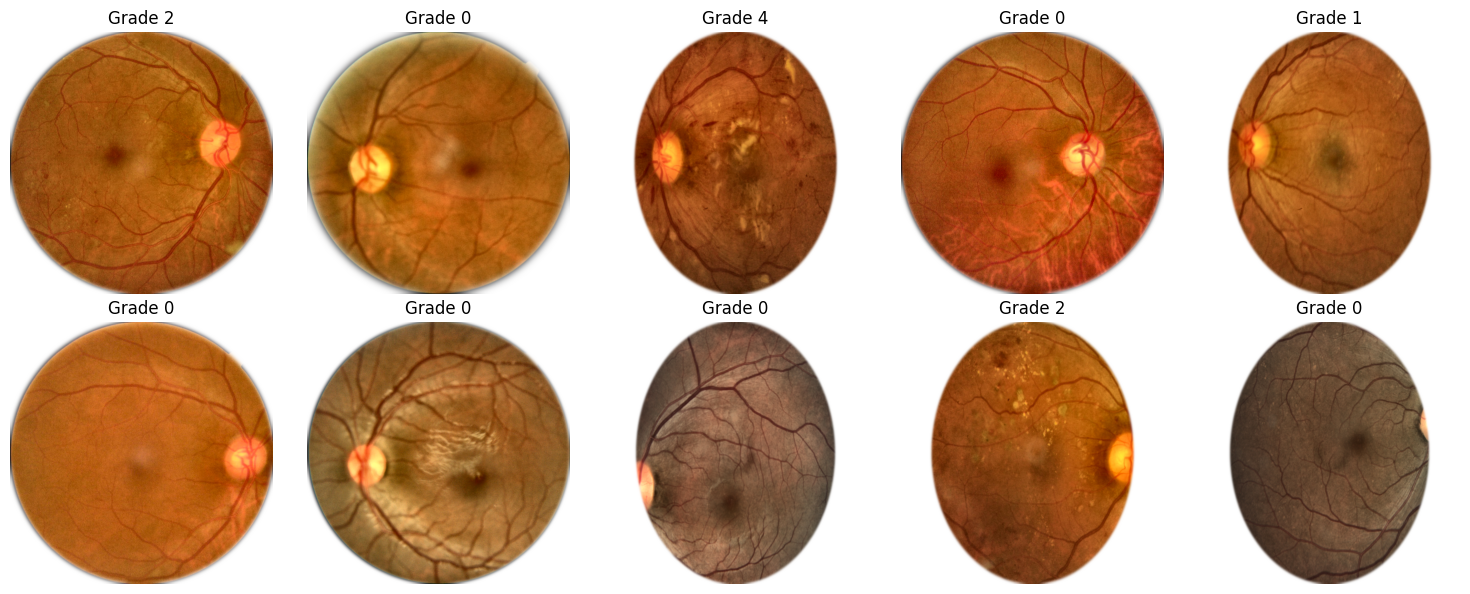

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, (_, row) in zip(axes.flat, train_df.sample(10, random_state=0).iterrows()):
    img = cv2.cvtColor(cv2.imread(row["filepath"]), cv2.COLOR_BGR2RGB)
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"Grade {row['diagnosis']}")
plt.tight_layout(); plt.show()

## RESNET-50

In [ ]:
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import (
    cohen_kappa_score,
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

EPOCHS, BS, LR = 15, 32, 3e-4
dev = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED)
np.random.seed(SEED)
print("Device:", dev)

In [ ]:
# Dataset + DataLoader (dùng lại train_df / val_df / test_df ở trên)
norm  = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
tf_tr = T.Compose([T.ToPILImage(), T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
                   T.RandomRotation(30), T.ColorJitter(0.2, 0.2), T.ToTensor(), norm])
tf_ev = T.Compose([T.ToPILImage(), T.ToTensor(), norm])

class APTOSDataset(Dataset):
    def __init__(self, df, tf): self.df, self.tf = df, tf
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        img = cv2.cvtColor(cv2.imread(r["filepath"]), cv2.COLOR_BGR2RGB)
        return self.tf(img), int(r["diagnosis"])

mk = lambda df, tf, sh: DataLoader(APTOSDataset(df, tf), BS, shuffle=sh, num_workers=2, pin_memory=True)
dl_tr, dl_va, dl_te = mk(train_df, tf_tr, True), mk(val_df, tf_ev, False), mk(test_df, tf_ev, False)

In [ ]:
# ResNet50 pretrained
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
model.fc = nn.Linear(model.fc.in_features, 5)
model = model.to(dev)

cw = torch.tensor([class_weight_dict[c] for c in range(5)], dtype=torch.float32, device=dev)
criterion = nn.CrossEntropyLoss(weight=cw)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, EPOCHS)
scaler = torch.amp.GradScaler(enabled=(dev == "cuda"))

In [ ]:
@torch.no_grad()
def predict(dl):
    model.eval(); P, Y = [], []
    for x, y in dl:
        with torch.autocast(dev, enabled=(dev == "cuda")):
            P += model(x.to(dev)).argmax(1).cpu().tolist()
        Y += y.tolist()
    return np.array(Y), np.array(P)

best_qwk, history = -1, []
for ep in range(EPOCHS):
    model.train(); tl = 0
    for x, y in tqdm(dl_tr, desc=f"Epoch {ep+1}/{EPOCHS}", leave=False):
        x, y = x.to(dev), y.to(dev)
        optimizer.zero_grad()
        with torch.autocast(dev, enabled=(dev == "cuda")):
            loss = criterion(model(x), y)
        scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        tl += loss.item() * len(y)
    scheduler.step()
    yv, pv = predict(dl_va)
    qwk = cohen_kappa_score(yv, pv, weights="quadratic")
    history.append((tl / len(train_df), accuracy_score(yv, pv), qwk))
    print(f"ep{ep+1:02d} loss={history[-1][0]:.4f} val_acc={history[-1][1]:.4f} val_QWK={qwk:.4f}")
    if qwk > best_qwk:
        best_qwk = qwk
        torch.save(model.state_dict(), OUTPUT_DIR / "best_resnet50.pt")

In [ ]:
# Đánh giá trên tập test
model.load_state_dict(torch.load(OUTPUT_DIR / "best_resnet50.pt"))
yt, pt = predict(dl_te)
print(f"Accuracy : {accuracy_score(yt, pt):.4f}")
print(f"QWK      : {cohen_kappa_score(yt, pt, weights='quadratic'):.4f}")
print(f"Macro-F1 : {f1_score(yt, pt, average='macro'):.4f}\n")
print(classification_report(yt, pt, digits=4))
print("Confusion matrix:\n", confusion_matrix(yt, pt))

In [ ]:
# Đồ thị huấn luyện + confusion matrix
h = np.array(history)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(h[:, 0]); ax[0].set_title("Train loss")
ax[1].plot(h[:, 1]); ax[1].set_title("Val accuracy")
ax[2].plot(h[:, 2]); ax[2].set_title("Val QWK")
plt.tight_layout(); plt.show()

cm = confusion_matrix(yt, pt)
plt.figure(figsize=(5, 4)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
for i in range(5):
    for j in range(5):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Test confusion matrix"); plt.show()